In [1]:
# Step 1: Data Import & Setup

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

df = pd.read_csv('social_media_engagement_5000.csv')

print(df.dtypes)
df['posted_at'] = pd.to_datetime(df['posted_at'], format='%d-%m-%Y')

likes_arr = df['likes'].dropna().to_numpy()
print("Mean Likes (NumPy):", np.mean(likes_arr))
print("Max Likes (NumPy):", np.max(likes_arr))

user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
dtype: object
Mean Likes (NumPy): 10107.043711340206
Max Likes (NumPy): 19998.0


In [2]:
# Task 2 — Data Cleaning

print("Missing values before cleaning:\n", df.isnull().sum()[df.isnull().sum() > 0])

df['age'] = df['age'].fillna(df['age'].median()).astype(int)
df['gender'] = df['gender'].fillna(df['gender'].mode()[0])
df['sentiment'] = df['sentiment'].fillna(df['sentiment'].mode()[0])

for col in ['likes', 'comments', 'shares']:
    df[col] = df[col].fillna(df[col].median())

duplicates_removed = df.duplicated().sum()
df = df.drop_duplicates()
print(f"\nDuplicates removed: {duplicates_removed}")

df['gender'] = df['gender'].str.strip().str.title()
df['sentiment'] = df['sentiment'].str.strip().str.lower()
df['post_type'] = df['post_type'].str.strip().str.lower()
df['post_category'] = df['post_category'].str.strip().str.lower()

for col in ['likes', 'comments', 'shares']:
    df[col] = df[col].clip(lower=0)

total_eng = df['likes'] + df['comments'] + df['shares']
unrealistic_mask = total_eng > df['impression_count']
print(f"Unrealistic rows corrected: {unrealistic_mask.sum()}")

scale_factor = df.loc[unrealistic_mask, 'impression_count'] / total_eng[unrealistic_mask]
for col in ['likes', 'comments', 'shares']:
    df.loc[unrealistic_mask, col] = np.floor(df.loc[unrealistic_mask, col] * scale_factor)
    df[col] = df[col].astype(int)

df['engagement_rate'] = (df['likes'] + df['comments'] + df['shares']) / df['impression_count']

df['hashtag_count'] = df['hashtags'].apply(lambda x: len([tag for tag in str(x).split() if tag.startswith('#')]))
print("Data cleaning completed! Remaining missing values:", df.isnull().sum().sum())

Missing values before cleaning:
 age          150
gender       150
likes        150
comments     150
shares       150
sentiment    150
dtype: int64

Duplicates removed: 0
Unrealistic rows corrected: 600
Data cleaning completed! Remaining missing values: 0


In [3]:
# Task 3 — Data Exploration using Pandas

display(df.head(5))
display(df.tail(3))
print("Dataset Shape:", df.shape)
print("\nData Types:\n", df.dtypes)


display(df.describe().round(2))


for col in ['post_type', 'post_category', 'country', 'sentiment', 'device_type']:
    print(f"\n--- {col} (Unique: {df[col].nunique()}) ---")
    print(df[col].value_counts())


num_cols = ['age', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'follower_count', 'engagement_rate']
corr_matrix = df[num_cols].corr()
display(corr_matrix.round(3))


print("\nAverage Likes by Post Type:\n", df.groupby('post_type')['likes'].mean().round(2))
print("\nAverage Impressions by Country:\n", df.groupby('country')['impression_count'].mean().sort_values(ascending=False).round(2))

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43,Female,Brazil,496713,image,fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33,Male,Brazil,157326,reel,food,11750,2606,1807,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493,1
2,86820,32,Female,UK,109864,text,food,4862,344,955,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345,1
3,64886,51,Other,France,848877,text,fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34,Other,UK,449706,image,fitness,4566,984,468,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,0.999834,1


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4997,67021,63,Female,USA,273595,text,travel,13487,1497,167,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.639823,2
4998,29800,13,Female,Germany,785644,video,fitness,16894,1289,1713,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518,3
4999,73400,54,Other,Japan,712252,text,travel,12322,417,1493,3743,14234,2023-03-04,585760,False,desktop,neutral,#foodie #lifestyle #fashion,0.999859,3


Dataset Shape: (5000, 20)

Data Types:
 user_id                      int64
age                          int64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                        int64
comments                     int64
shares                       int64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                      str
hashtags                       str
engagement_rate            float64
hashtag_count                int64
dtype: object


,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000,5000.00,5000.00,5000.00
mean,54561.89,38.44,548042.91,9337.23,1410.72,940.28,4014.50,50013.73,2022-12-28 13:21:30.240000,393698.22,0.37,2.00
min,10055.00,13.00,100068.00,0.00,0.00,0.00,0.00,105.00,2022-01-01 00:00:00,87.00,0.01,1.00
25%,32309.50,26.00,322543.50,4394.25,648.00,424.00,2017.75,24988.25,2022-07-03 18:00:00,194480.00,0.15,1.00
50%,54374.50,38.00,548077.50,9237.00,1404.50,950.00,4034.50,49934.50,2022-12-27 00:00:00,388982.00,0.25,2.00
75%,77180.50,51.00,771574.50,14010.25,2149.25,1419.00,6020.25,74662.25,2023-06-28 00:00:00,589744.25,0.50,3.00
max,99963.00,64.00,999455.00,19998.00,2999.00,1999.00,7998.00,99995.00,2023-12-31 00:00:00,799533.00,1.00,3.00
std,26090.37,14.69,260646.96,5676.61,867.00,577.65,2308.10,28844.94,NaN,230927.88,0.30,0.81



--- post_type (Unique: 4) ---
post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64

--- post_category (Unique: 8) ---
post_category
fitness      675
tech         665
music        635
education    631
lifestyle    607
travel       600
fashion      594
food         593
Name: count, dtype: int64

--- country (Unique: 10) ---
country
India        535
Canada       513
Brazil       504
UAE          503
USA          501
France       496
UK           493
Australia    493
Germany      490
Japan        472
Name: count, dtype: int64

--- sentiment (Unique: 3) ---
sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64

--- device_type (Unique: 3) ---
device_type
mobile     1684
tablet     1658
desktop    1658
Name: count, dtype: int64


,age,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate
age,1.000,-0.031,-0.005,0.010,0.006,0.013,-0.025,-0.025
likes,-0.031,1.000,0.072,0.094,0.001,0.217,-0.025,0.116
comments,-0.005,0.072,1.000,0.109,-0.024,0.154,-0.007,-0.153
shares,0.010,0.094,0.109,1.000,0.007,0.164,-0.004,-0.174
watch_time_sec,0.006,0.001,-0.024,0.007,1.000,-0.004,0.003,0.015
impression_count,0.013,0.217,0.154,0.164,-0.004,1.000,-0.016,-0.786
follower_count,-0.025,-0.025,-0.007,-0.004,0.003,-0.016,1.000,-0.004
engagement_rate,-0.025,0.116,-0.153,-0.174,0.015,-0.786,-0.004,1.000



Average Likes by Post Type:
 post_type
image    9337.20
reel     9395.86
text     9290.51
video    9323.34
Name: likes, dtype: float64

Average Impressions by Country:
 country
India        52462.39
France       51727.67
USA          51263.87
UK           51119.39
Japan        49616.14
Brazil       49193.17
UAE          48928.41
Canada       48703.15
Germany      48605.41
Australia    48346.38
Name: impression_count, dtype: float64


In [4]:
# Task 4 — Data Wrangling

df['engagement_score'] = df['likes'] + (2 * df['comments']) + (3 * df['shares'])
df['log_impressions'] = np.log1p(df['impression_count'])
df['day_of_week'] = df['posted_at'].dt.day_name()
df['month'] = df['posted_at'].dt.to_period('M').astype(str)

region_map = pd.DataFrame({
    'country': ['USA', 'UK', 'Canada', 'Germany', 'France', 'Australia', 'Japan', 'UAE', 'India', 'Brazil'],
    'market_tier': ['Tier 1']*7 + ['Emerging']*3
})
df = pd.merge(df, region_map, on='country', how='left')


print("--- Summary by Post Type ---")
display(df.groupby('post_type')[['likes', 'comments', 'shares', 'engagement_rate', 'engagement_score']].mean().round(4))

print("--- Summary by Country ---")
display(df.groupby('country')[['impression_count', 'engagement_rate', 'engagement_score']].mean().sort_values(by='engagement_rate', ascending=False).round(4))

print("--- Summary by Sentiment ---")
display(df.groupby('sentiment')[['likes', 'comments', 'shares', 'watch_time_sec', 'engagement_rate']].mean().round(4))

--- Summary by Post Type ---


,likes,comments,shares,engagement_rate,engagement_score
post_type,,,,,
image,9337.1973,1437.8388,957.4298,0.3732,15085.1644
reel,9395.8597,1423.9860,929.2081,0.3599,15031.4560
text,9290.5060,1404.5622,943.5663,0.3768,14930.3293
video,9323.3412,1375.4580,931.0645,0.3762,14867.4506


--- Summary by Country ---


,impression_count,engagement_rate,engagement_score
country,,,
Australia,48346.3834,0.3953,14802.8337
Japan,49616.1356,0.3848,14842.9767
UAE,48928.4135,0.3825,14752.9821
Germany,48605.4061,0.3801,15256.0184
Canada,48703.1501,0.3772,15051.0994
Brazil,49193.1746,0.3741,14830.9524
France,51727.6734,0.3672,15102.3185
USA,51263.8723,0.3584,15029.4232
UK,51119.3935,0.3561,14866.8702


--- Summary by Sentiment ---


,likes,comments,shares,watch_time_sec,engagement_rate
sentiment,,,,,
negative,9255.6917,1410.1969,933.0312,4054.6396,0.3750
neutral,9166.7970,1437.9306,935.5763,4031.8232,0.3750
positive,9471.9391,1394.3756,945.9005,3988.6462,0.3679


In [5]:
# Task 5 — Statistical Analysis

stat_cols = ['likes', 'comments', 'shares', 'watch_time_sec', 'engagement_rate', 'follower_count']

stats_summary = pd.DataFrame({
    'Mean': df[stat_cols].mean(),
    'Median': df[stat_cols].median(),
    'Mode': df[stat_cols].mode().iloc[0],
    'Std Dev': df[stat_cols].std(),
    'Variance': df[stat_cols].var(),
    '25th Percentile': df[stat_cols].quantile(0.25),
    '50th Percentile': df[stat_cols].quantile(0.50),
    '75th Percentile': df[stat_cols].quantile(0.75),
    'Skewness': df[stat_cols].skew(),
    'Kurtosis': df[stat_cols].kurt()
})

display(stats_summary.round(4))

,Mean,Median,Mode,Std Dev,Variance,25th Percentile,50th Percentile,75th Percentile,Skewness,Kurtosis
likes,9337.2292,9237.0000,10105.0000,5676.6079,3.222388e+07,4394.2500,9237.0000,14010.2500,0.1406,-1.1199
comments,1410.7150,1404.5000,1497.0000,867.0030,7.516942e+05,648.0000,1404.5000,2149.2500,0.1049,-1.1600
shares,940.2766,950.0000,1012.0000,577.6490,3.336784e+05,424.0000,950.0000,1419.0000,0.0912,-1.1659
watch_time_sec,4014.5032,4034.5000,916.0000,2308.0965,5.327309e+06,2017.7500,4034.5000,6020.2500,-0.0182,-1.1957
engagement_rate,0.3714,0.2547,0.9974,0.3037,9.220000e-02,0.1469,0.2547,0.5039,1.0644,-0.1809
follower_count,393698.2248,388982.0000,497502.0000,230927.8845,5.332769e+10,194480.0000,388982.0000,589744.2500,0.0411,-1.1895


C:\Users\ABHIJITH\AppData\Local\Temp\ipykernel_17740\2078754096.py:37: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[2, 1].boxplot(df['engagement_rate'], vert=False, patch_artist=True, boxprops=dict(facecolor='lightblue'))


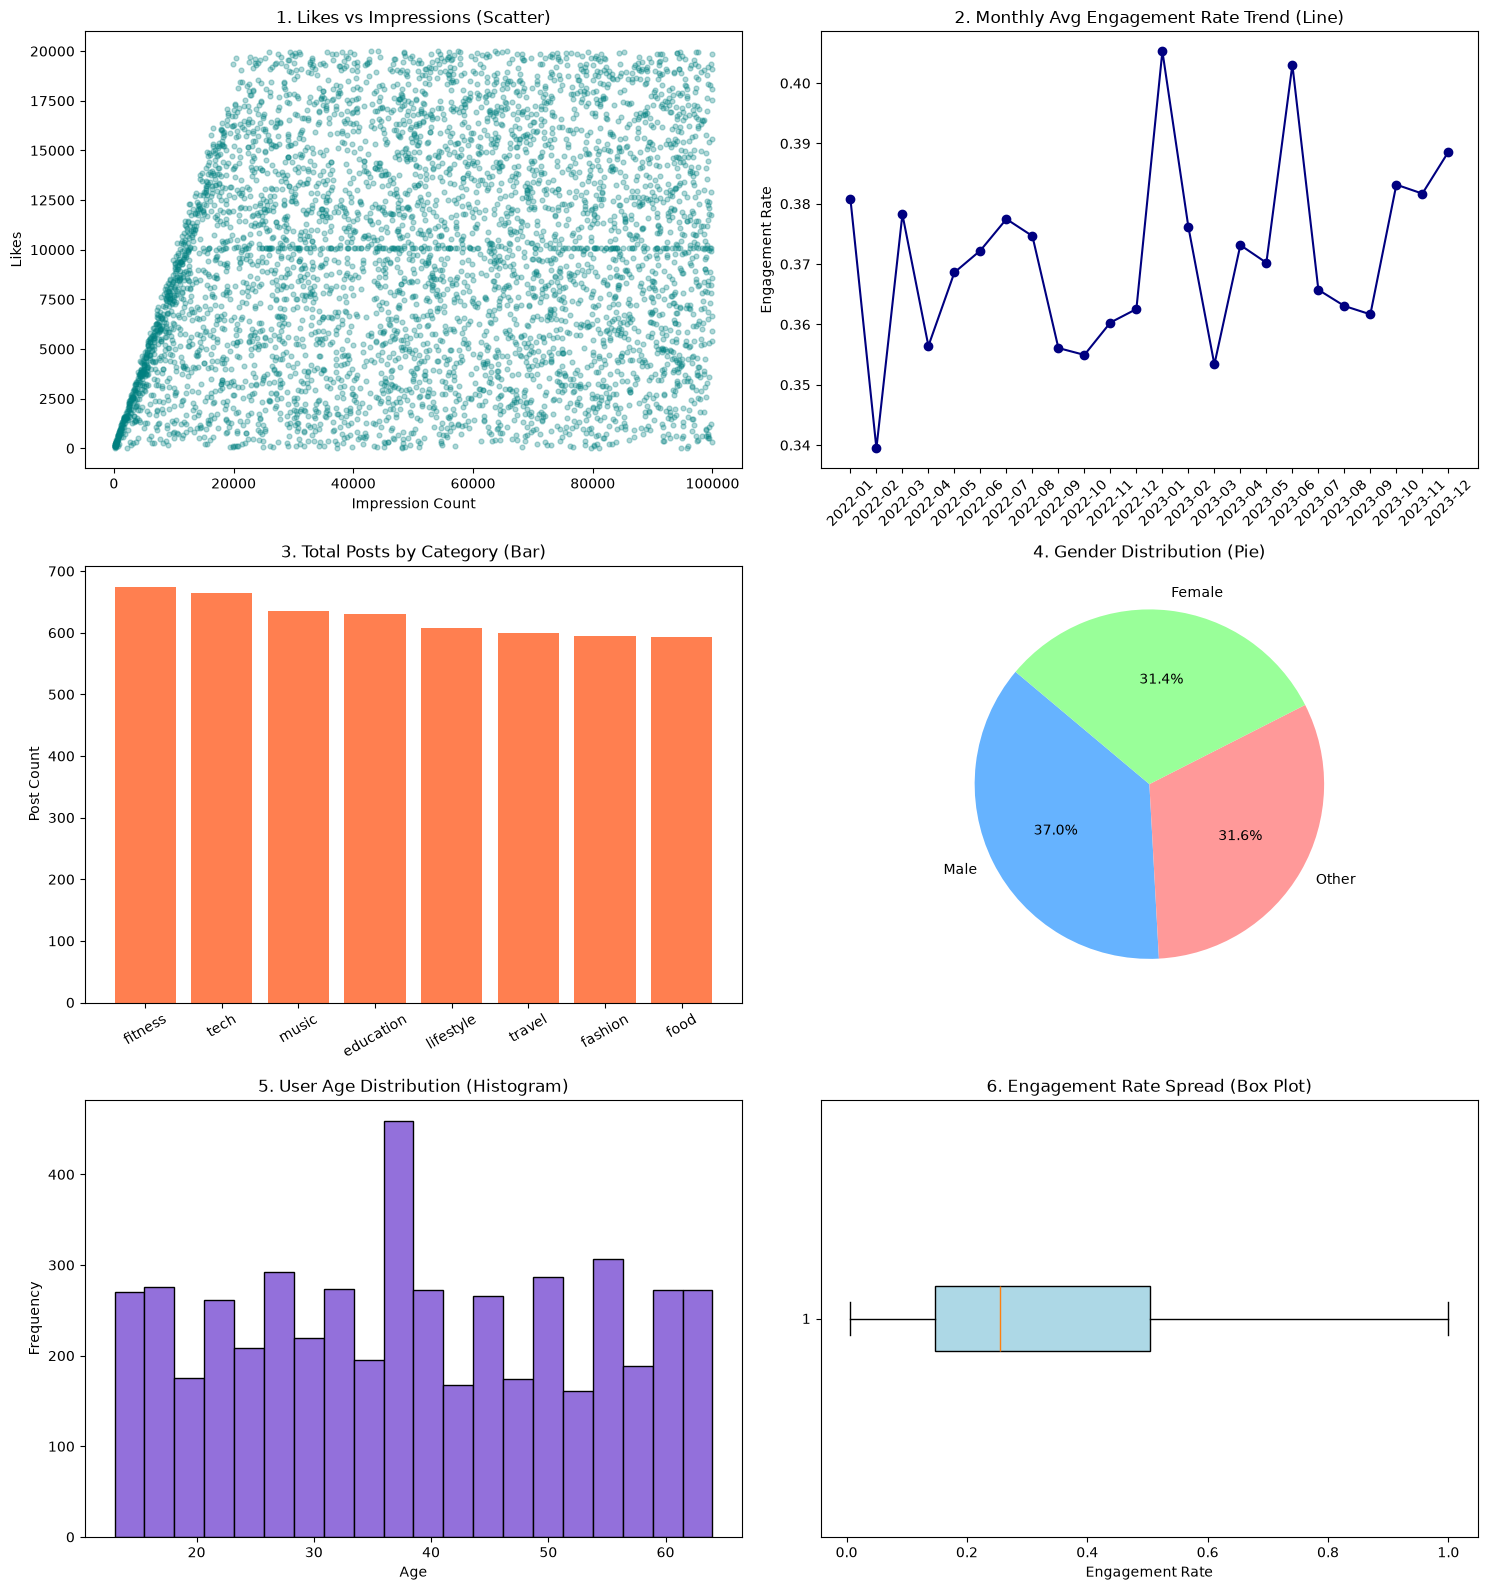

In [6]:
# Task 6A — Matplotlib Visualizations (6 Plots)

fig, axes = plt.subplots(3, 2, figsize=(15, 16))

# 1. Scatter: Likes vs Impressions
axes[0, 0].scatter(df['impression_count'], df['likes'], alpha=0.3, color='teal', s=12)
axes[0, 0].set_title('1. Likes vs Impressions (Scatter)')
axes[0, 0].set_xlabel('Impression Count')
axes[0, 0].set_ylabel('Likes')

# 2. Line: Monthly Engagement Rate Trend
monthly_trend = df.groupby('month')['engagement_rate'].mean()
axes[0, 1].plot(monthly_trend.index, monthly_trend.values, marker='o', color='navy')
axes[0, 1].set_title('2. Monthly Avg Engagement Rate Trend (Line)')
axes[0, 1].set_ylabel('Engagement Rate')
axes[0, 1].tick_params(axis='x', rotation=45)

# 3. Bar: Posts by Category
cat_counts = df['post_category'].value_counts()
axes[1, 0].bar(cat_counts.index, cat_counts.values, color='coral')
axes[1, 0].set_title('3. Total Posts by Category (Bar)')
axes[1, 0].set_ylabel('Post Count')
axes[1, 0].tick_params(axis='x', rotation=30)

# 4. Pie: Gender Distribution
gender_counts = df['gender'].value_counts()
axes[1, 1].pie(gender_counts.values, labels=gender_counts.index, autopct='%1.1f%%', startangle=140, colors=['#66b3ff', '#ff9999', '#99ff99'])
axes[1, 1].set_title('4. Gender Distribution (Pie)')

# 5. Histogram: Age
axes[2, 0].hist(df['age'], bins=20, color='mediumpurple', edgecolor='black')
axes[2, 0].set_title('5. User Age Distribution (Histogram)')
axes[2, 0].set_xlabel('Age')
axes[2, 0].set_ylabel('Frequency')

# 6. Box Plot: Engagement Rate
axes[2, 1].boxplot(df['engagement_rate'], vert=False, patch_artist=True, boxprops=dict(facecolor='lightblue'))
axes[2, 1].set_title('6. Engagement Rate Spread (Box Plot)')
axes[2, 1].set_xlabel('Engagement Rate')

plt.tight_layout()
plt.show()

In [7]:
import sys
!{sys.executable} -m pip install nbformat

'c:\Users\ABHIJITH\Desktop\Data' is not recognized as an internal or external command,
operable program or batch file.


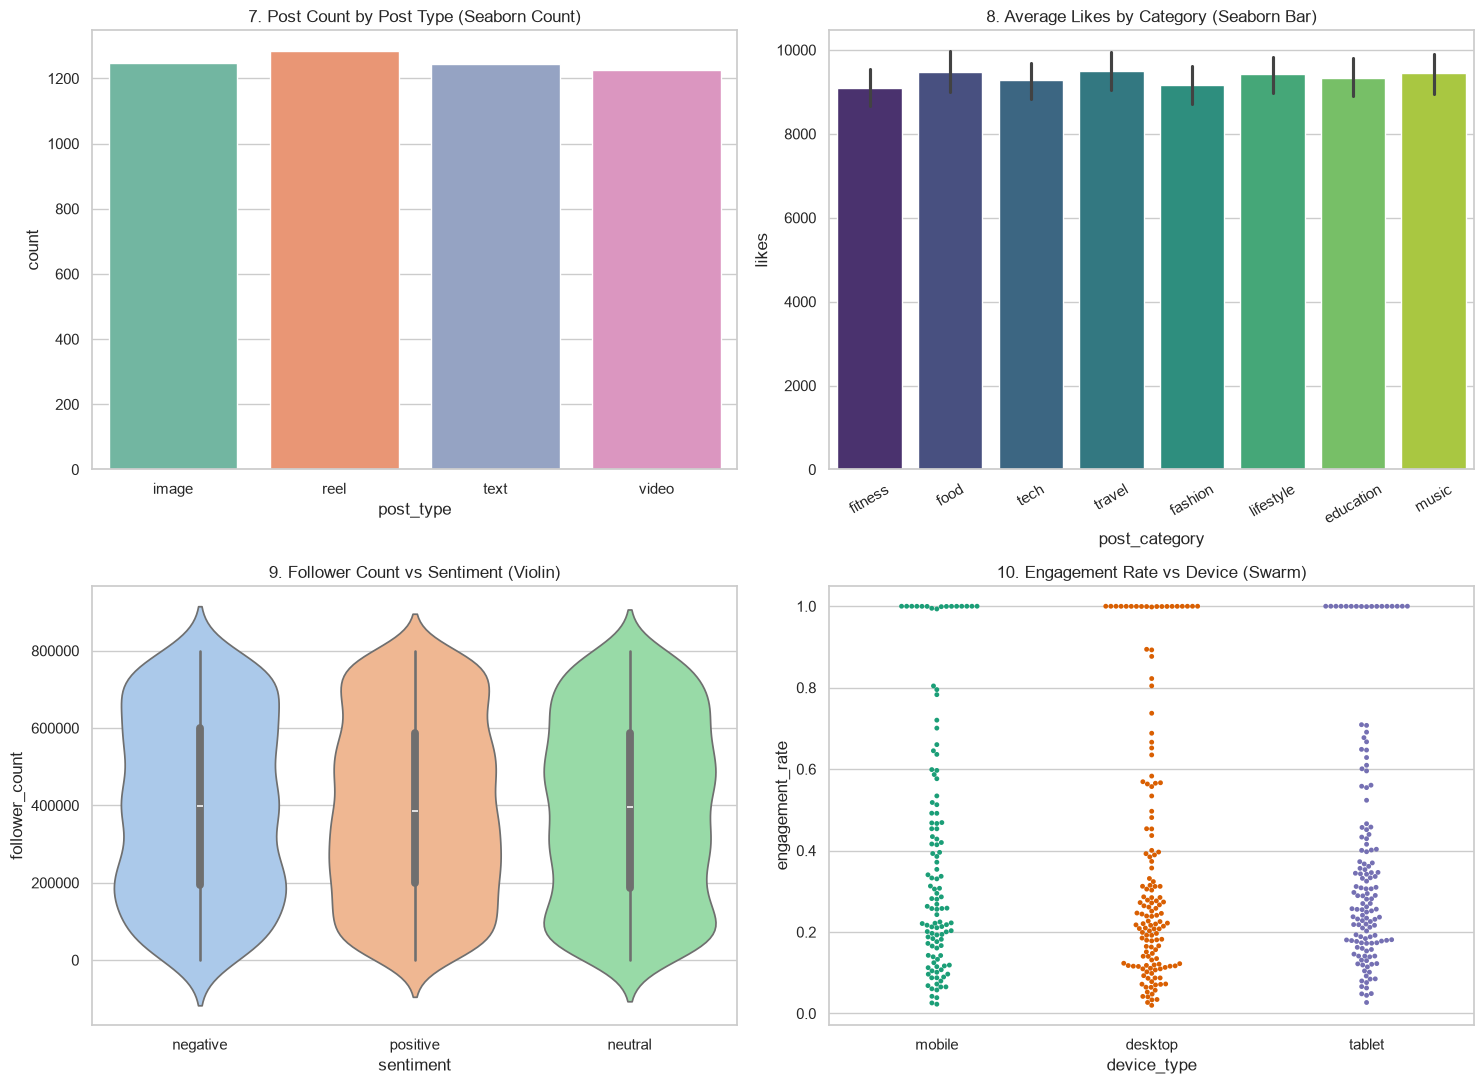

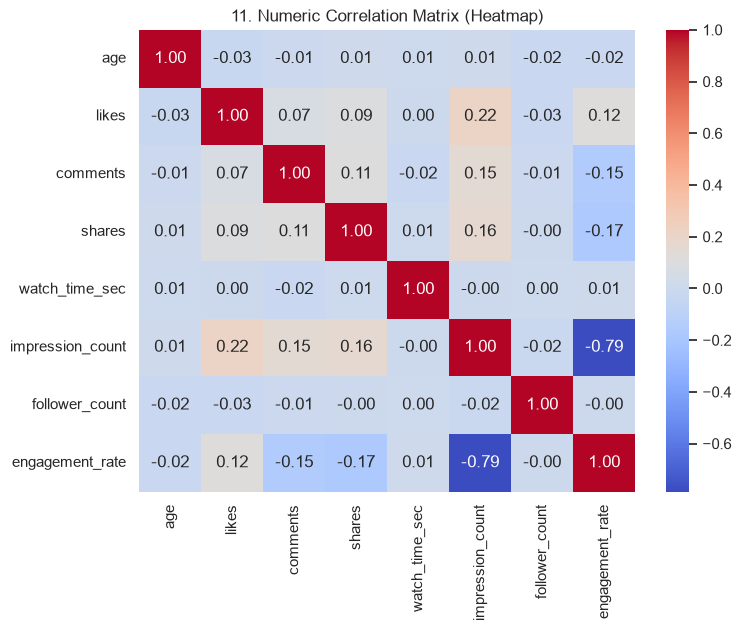

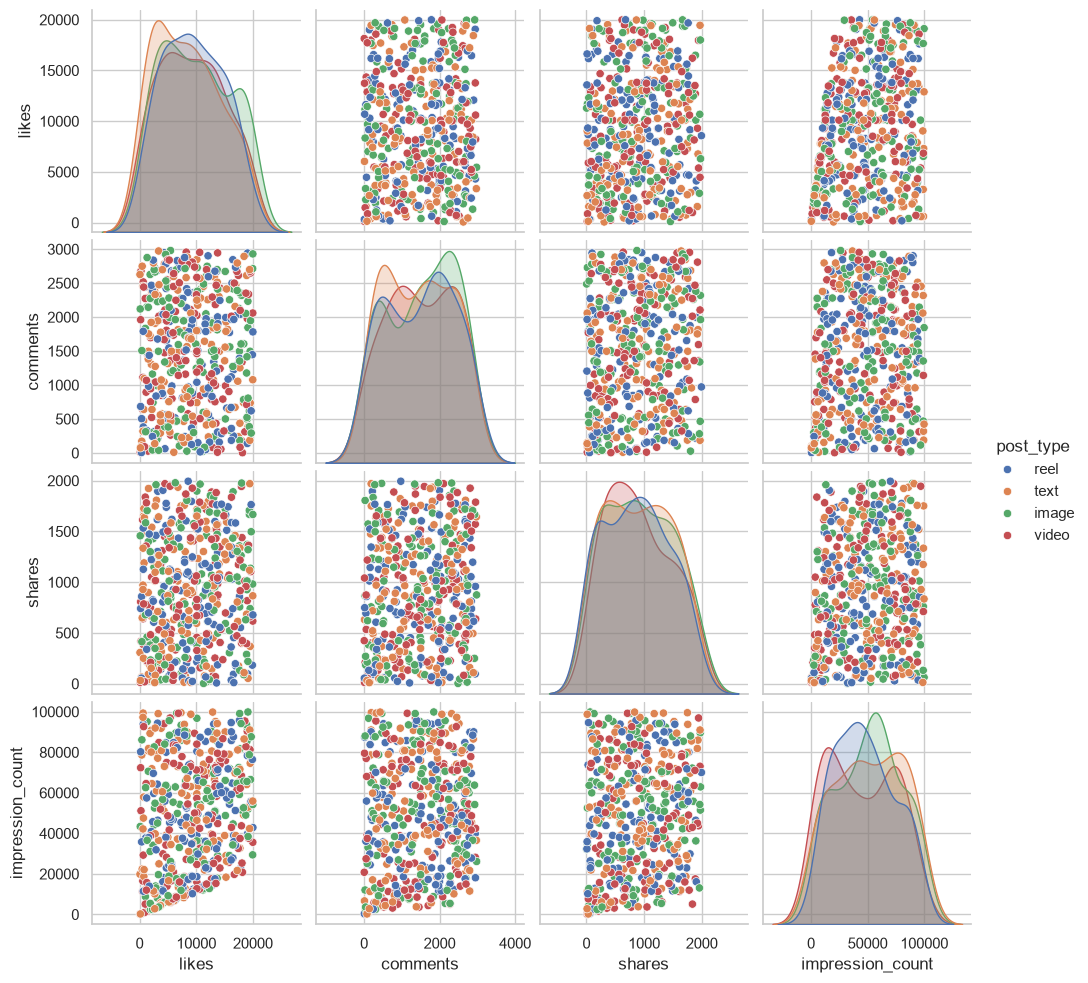

In [8]:
# Task 6B — Seaborn & Plotly Visualizations (7 Plots)

sns.set_theme(style="whitegrid")
fig2, axes2 = plt.subplots(2, 2, figsize=(15, 11))

# 7. Seaborn Count Plot: Post Type
sns.countplot(data=df, x='post_type', ax=axes2[0, 0], palette='Set2', hue='post_type', legend=False)
axes2[0, 0].set_title('7. Post Count by Post Type (Seaborn Count)')

# 8. Seaborn Bar Plot: Avg Likes by Category
sns.barplot(data=df, x='post_category', y='likes', ax=axes2[0, 1], palette='viridis', hue='post_category', legend=False)
axes2[0, 1].set_title('8. Average Likes by Category (Seaborn Bar)')
axes2[0, 1].tick_params(axis='x', rotation=30)

# 9. Seaborn Violin Plot: Followers vs Sentiment
sns.violinplot(data=df, x='sentiment', y='follower_count', ax=axes2[1, 0], palette='pastel', hue='sentiment', legend=False)
axes2[1, 0].set_title('9. Follower Count vs Sentiment (Violin)')

# 10. Seaborn Swarm Plot: Engagement Rate vs Device (400 sample for speed)
sns.swarmplot(data=df.sample(400, random_state=42), x='device_type', y='engagement_rate', ax=axes2[1, 1], size=3.5, palette='Dark2', hue='device_type', legend=False)
axes2[1, 1].set_title('10. Engagement Rate vs Device (Swarm)')

plt.tight_layout()
plt.show()

# 11. Seaborn Heatmap: Correlation Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('11. Numeric Correlation Matrix (Heatmap)')
plt.show()

# 12. Seaborn Pair Plot: Numeric Features
sns.pairplot(df[['likes', 'comments', 'shares', 'impression_count', 'post_type']].sample(500, random_state=42), hue='post_type')
plt.show()

# 13. Plotly Interactive Bubble Chart
country_summary = df.groupby('country', as_index=False)[['impression_count', 'engagement_rate', 'likes']].mean()
fig_plotly = px.scatter(
    country_summary, x='impression_count', y='engagement_rate',
    size='likes', color='country', text='country',
    title='13. Interactive: Avg Impressions vs. Engagement Rate by Country'
)
fig_plotly.show()